# 01 - Exploratory Data Analysis: Bangalore road-network traffic

**Goal.** Build a fast deep-learning *surrogate* of a high-fidelity traffic simulator: given the scenario on a road
(traffic volume, incidents, weather, roadwork, ...), predict the congestion class and speed in one forward pass.

**Dataset.** Kaggle `preethamgouda/banglore-city-traffic-dataset` (reported by its author to derive from Government of
Karnataka open traffic data; provenance not independently verified). 8,936 rows, 16 roads in 8 areas, 2022-01-01 to 2024-08-09.

This notebook checks data quality and, importantly, whether the data has temporal/spatial structure. The findings decide the task design.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from traffic.data import load_frame, build, NUMERIC, CLASS_NAMES, CLASS_CUTS
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
d = load_frame()
raw = pd.read_csv("../data/raw/Banglore_traffic_Dataset.csv")
print(raw.shape); raw.head()

(8936, 16)


,Date,Area Name,Road/Intersection Name,Traffic Volume,Average Speed,Travel Time Index,Congestion Level,Road Capacity Utilization,Incident Reports,Environmental Impact,Public Transport Usage,Traffic Signal Compliance,Parking Usage,Pedestrian and Cyclist Count,Weather Conditions,Roadwork and Construction Activity
0,2022-01-01,Indiranagar,100 Feet Road,50590,50.230299,1.500000,100.000000,100.000000,0,151.180,70.632330,84.044600,85.403629,111,Clear,No
1,2022-01-01,Indiranagar,CMH Road,30825,29.377125,1.500000,100.000000,100.000000,1,111.650,41.924899,91.407038,59.983689,100,Clear,No
2,2022-01-01,Whitefield,Marathahalli Bridge,7399,54.474398,1.039069,28.347994,36.396525,0,64.798,44.662384,61.375541,95.466020,189,Clear,No
3,2022-01-01,Koramangala,Sony World Junction,60874,43.817610,1.500000,100.000000,100.000000,1,171.748,32.773123,75.547092,63.567452,111,Clear,No
4,2022-01-01,Koramangala,Sarjapur Road,57292,41.116763,1.500000,100.000000,100.000000,3,164.584,35.092601,64.634762,93.155171,104,Clear,No


## 1. Data quality

In [2]:
print("missing values:", int(raw.isna().sum().sum()), "| duplicate rows:", int(raw.duplicated().sum()))
print(raw.dtypes.to_string())
raw.describe().T[["mean","std","min","50%","max"]].round(2)

missing values: 0 | duplicate rows: 0
Date                                      str
Area Name                                 str
Road/Intersection Name                    str
Traffic Volume                          int64
Average Speed                         float64
Travel Time Index                     float64
Congestion Level                      float64
Road Capacity Utilization             float64
Incident Reports                        int64
Environmental Impact                  float64
Public Transport Usage                float64
Traffic Signal Compliance             float64
Parking Usage                         float64
Pedestrian and Cyclist Count            int64
Weather Conditions                        str
Roadwork and Construction Activity        str


,mean,std,min,50%,max
Traffic Volume,29236.05,13001.81,4233.00,27600.00,72039.00
Average Speed,39.45,10.71,20.00,39.20,89.79
Travel Time Index,1.38,0.17,1.00,1.50,1.50
Congestion Level,80.82,23.53,5.16,92.39,100.00
Road Capacity Utilization,92.03,16.58,18.74,100.00,100.00
Incident Reports,1.57,1.42,0.00,1.00,10.00
Environmental Impact,108.47,26.00,58.47,105.20,194.08
Public Transport Usage,45.09,20.21,10.01,45.17,79.98
Traffic Signal Compliance,79.95,11.59,60.00,79.99,99.99
Parking Usage,75.16,14.41,50.02,75.32,100.00


## 2. Targets and saturation

`Congestion Level`, `Road Capacity Utilization` and `Travel Time Index` are **capped** (100, 100, 1.5). A large share of rows sit at the cap,
so these columns carry little information beyond "saturated" - they are treated as *outcomes* and excluded from the model inputs.

Congestion Level: 43.5% of rows at the cap
Road Capacity Utilization: 73.7% of rows at the cap
Travel Time Index: 58.5% of rows at the cap


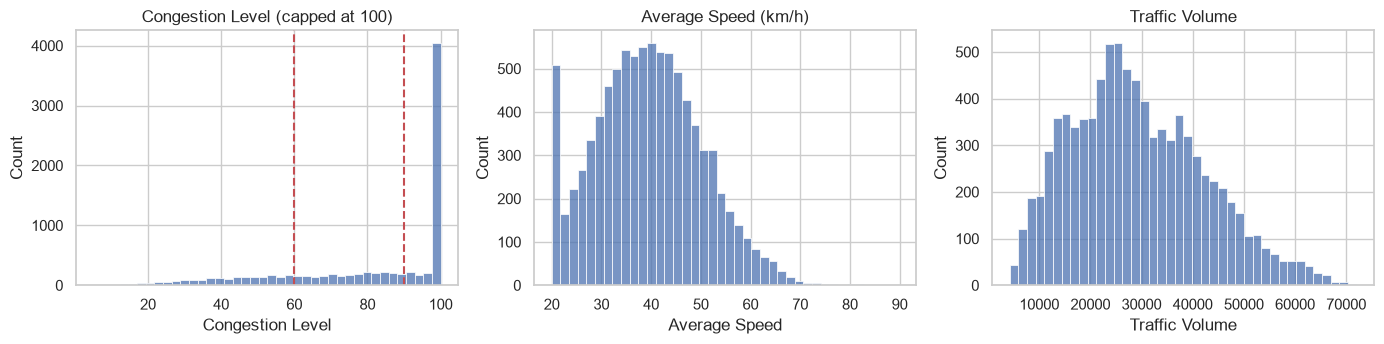

In [3]:
for c, cap in [("Congestion Level",100),("Road Capacity Utilization",100),("Travel Time Index",1.5)]:
    print(f"{c}: {(raw[c] >= cap-1e-4).mean():.1%} of rows at the cap")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
sns.histplot(raw["Congestion Level"], bins=40, ax=ax[0]); ax[0].set_title("Congestion Level (capped at 100)")
for c in CLASS_CUTS: ax[0].axvline(c, color="r", ls="--")
sns.histplot(raw["Average Speed"], bins=40, ax=ax[1]); ax[1].set_title("Average Speed (km/h)")
sns.histplot(raw["Traffic Volume"], bins=40, ax=ax[2]); ax[2].set_title("Traffic Volume")
plt.tight_layout(); plt.savefig(FIG/"eda_distributions.png", dpi=150); plt.show()

**Congestion class.** Cut-offs are fixed at 60 and 90 (Low < 60 <= Medium < 90 <= High). Fixed cut-offs are used because quantile bins would
collapse on the 43% of rows stuck at 100.

Class
High      0.523
Medium    0.259
Low       0.218
Name: proportion, dtype: float64


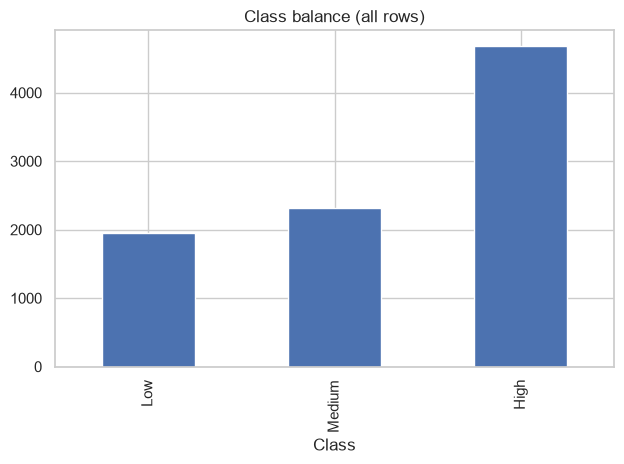

In [4]:
cls = d["Class"].map(dict(enumerate(CLASS_NAMES)))
print(cls.value_counts(normalize=True).round(3))
cls.value_counts().reindex(CLASS_NAMES).plot.bar(title="Class balance (all rows)"); plt.tight_layout()
plt.savefig(FIG/"eda_class_balance.png", dpi=150); plt.show()

## 3. Relationships between variables

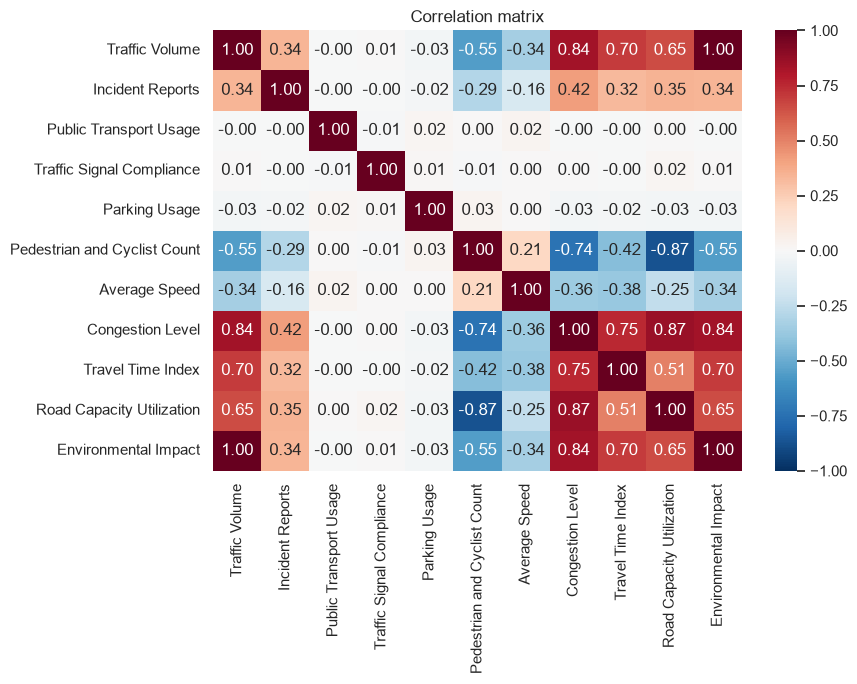

In [5]:
cols = NUMERIC + ["Average Speed","Congestion Level","Travel Time Index","Road Capacity Utilization","Environmental Impact"]
plt.figure(figsize=(9,7)); sns.heatmap(raw[cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix"); plt.tight_layout(); plt.savefig(FIG/"eda_correlation.png", dpi=150); plt.show()

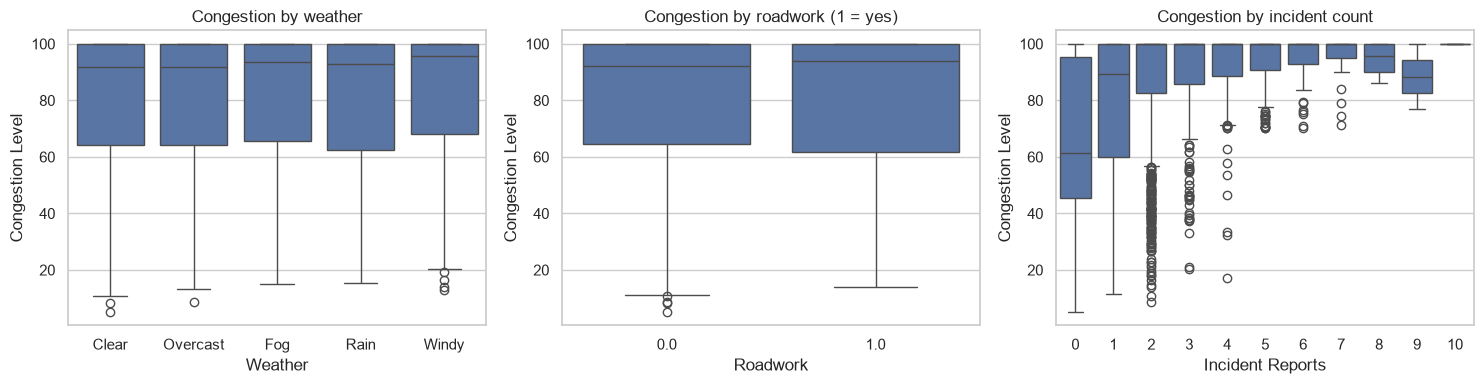

Weather effect on mean congestion:
 Weather
Clear       80.7
Fog         81.6
Overcast    80.3
Rain        80.5
Windy       82.4


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=d, x="Weather", y="Congestion Level", ax=ax[0]); ax[0].set_title("Congestion by weather")
sns.boxplot(data=d, x="Roadwork", y="Congestion Level", ax=ax[1]); ax[1].set_title("Congestion by roadwork (1 = yes)")
sns.boxplot(data=d, x="Incident Reports", y="Congestion Level", ax=ax[2]); ax[2].set_title("Congestion by incident count")
plt.tight_layout(); plt.savefig(FIG/"eda_drivers.png", dpi=150); plt.show()
print("Weather effect on mean congestion:\n", d.groupby("Weather")["Congestion Level"].mean().round(1).to_string())

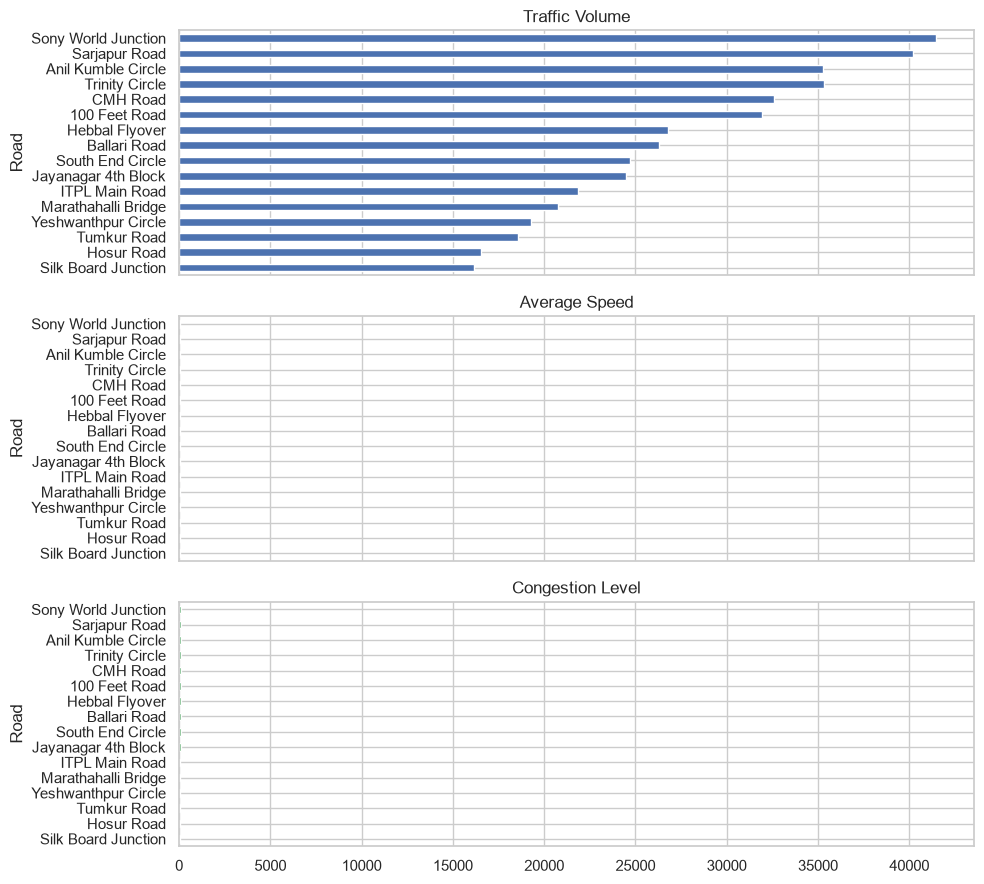

In [7]:
g = d.groupby("Road")[["Traffic Volume","Average Speed","Congestion Level"]].mean().sort_values("Congestion Level")
g.plot.barh(subplots=True, figsize=(10, 9), legend=False); plt.tight_layout()
plt.savefig(FIG/"eda_per_road.png", dpi=150); plt.show()

## 4. Does the data have temporal or spatial structure?

A forecasting model (e.g. an ST-GNN predicting tomorrow from the past week) only makes sense if today predicts tomorrow, or if neighbouring roads
move together. We test both directly rather than assuming it.

In [8]:
full = pd.date_range(d.Date.min(), d.Date.max())
rows = []
for c in ["Traffic Volume","Average Speed","Congestion Level"]:
    ac = [d[d.Road==r].set_index("Date")[c].reindex(full).pipe(lambda s: s.corr(s.shift(1))) for r in sorted(d.Road.unique())]
    rows.append((c, np.nanmean(ac)))
print("Mean lag-1 autocorrelation per road (day t vs day t-1):")
for c, v in rows: print(f"  {c:18s} {v:+.3f}")
p = d.pivot(index="Date", columns="Road", values="Average Speed")
cc = p.corr().values
print(f"Mean pairwise same-day speed correlation between roads: {np.nanmean(cc[np.triu_indices(16,1)]):+.3f}")
print("\nDay-of-week mean speed (km/h):", d.groupby(d.Date.dt.dayofweek)["Average Speed"].mean().round(1).tolist())
print("Roads observed per date:", d.groupby("Date").size().describe()[["mean","min","max"]].round(1).to_dict(),
      "| cells observed: %.1f%% of date x road grid" % (100*len(d)/(d.Date.nunique()*16)))
print("Distinct weather values on a single date (should be 1 if weather were city-wide):",
      d.groupby("Date")["Weather"].nunique().mean().round(2))

Mean lag-1 autocorrelation per road (day t vs day t-1):
  Traffic Volume     +0.008
  Average Speed      -0.004
  Congestion Level   +0.006
Mean pairwise same-day speed correlation between roads: -0.001

Day-of-week mean speed (km/h): [39.2, 39.5, 39.4, 39.5, 39.5, 39.6, 39.4]
Roads observed per date: {'mean': 9.4, 'min': 4.0, 'max': 15.0} | cells observed: 58.7% of date x road grid
Distinct weather values on a single date (should be 1 if weather were city-wide): 3.36


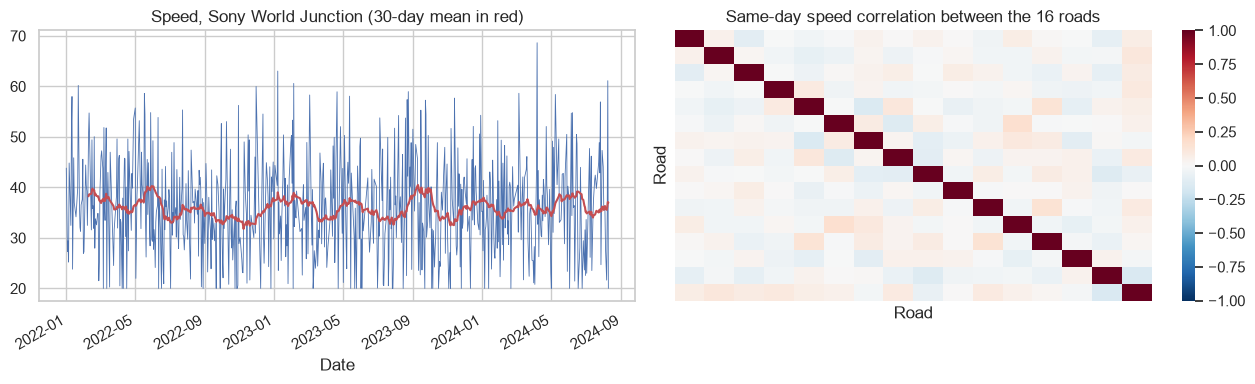

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
r = d[d.Road=="Sony World Junction"].set_index("Date")["Average Speed"]
r.plot(ax=ax[0], lw=.6); r.rolling(30).mean().plot(ax=ax[0], color="r"); ax[0].set_title("Speed, Sony World Junction (30-day mean in red)")
sns.heatmap(p.corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax[1], xticklabels=False, yticklabels=False)
ax[1].set_title("Same-day speed correlation between the 16 roads")
plt.tight_layout(); plt.savefig(FIG/"eda_temporal_spatial.png", dpi=150); plt.show()

## 5. Conclusions that drive the design

1. **Clean data**: no missing values or duplicates; weather is a per-row value (not city-wide) and 41% of the date x road grid is simply unobserved. Weather has almost no effect on congestion (mean congestion 80.3-82.4 across all five weather types), so expect it to add little predictive power.
2. **No temporal signal**: day-to-day autocorrelation is about 0, there is no weekly pattern and no trend. A next-day *forecasting* task has nothing to learn, so we do **not** build one.
3. **No spatial signal**: roads are uncorrelated on the same day. A graph model is still built (the project is about a road network) but the evaluation will report honestly whether it helps.
4. **Strong same-row signal**: traffic volume (r = 0.84 with congestion) plus road identity and local conditions determine congestion. The task is therefore a **scenario -> outcome surrogate**: predict congestion class (Low/Medium/High) and speed from the road's conditions.
5. **Leakage control**: Congestion Level, Capacity Utilization, Travel Time Index and Environmental Impact are outcomes, so they are not model inputs. Split is chronological 80/10/10 by date, and scalers are fit on the training period only.

In [10]:
ds = build()
for name in ("train","val","test"):
    s = getattr(ds, name)
    print(f"{name:5s} days={len(s.dates):4d} rows={int(s.mask.sum()):5d}  {str(s.dates[0])[:10]} -> {str(s.dates[-1])[:10]}")

train days= 761 rows= 7145  2022-01-01 -> 2024-01-31
val   days=  95 rows=  891  2024-02-01 -> 2024-05-05
test  days=  96 rows=  900  2024-05-06 -> 2024-08-09
